In [1]:
import pandas as pd

In [ ]:
df = pd.read_csv('/kaggle/input/Suicide_Detection.csv')
df.head()

In [9]:
df.drop(columns = 'Unnamed: 0' , inplace = True)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232074 entries, 0 to 232073
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    232074 non-null  object
 1   class   232074 non-null  object
dtypes: object(2)
memory usage: 3.5+ MB


In [11]:
df['class'].replace({'suicide':1 , 'non-suicide':0} , inplace = True)

In [12]:
from bs4 import BeautifulSoup

def strip_html_tags(text):
  soup = BeautifulSoup(text, "html.parser")
  [s.extract() for s in soup(['iframe', 'script'])]
  stripped_text = soup.get_text()
  stripped_text = re.sub(r'[\r|\n|\r\n]+', '\n', stripped_text)
  return stripped_text

def remove_accented_chars(text):
  text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('utf-8', 'ignore')
  return text

def stopwords_removal(words):
    list_stopwords = nltk.corpus.stopwords.words('english')
    return [word for word in words if word not in list_stopwords]

In [ ]:
!pip install contractions

In [14]:
import re
import nltk
import tqdm
import unicodedata
import contractions

from nltk.tokenize import word_tokenize

def pre_process_corpus(docs):
  norm_docs = []
  for doc in tqdm.tqdm(docs):
    #case folding
    doc = doc.lower()
    #remove special characters\whitespaces
    doc = strip_html_tags(doc)
    doc = doc.translate(doc.maketrans("\n\t\r", "   "))
    doc = remove_accented_chars(doc)
    doc = contractions.fix(doc)
    doc = re.sub(r'[^a-zA-Z0-9\s]', '', doc, re.I|re.A)
    doc = re.sub(' +', ' ', doc)
    doc = doc.strip()
    #tokenize
    doc = word_tokenize(doc)
    #filtering
    doc = stopwords_removal(doc)
    norm_docs.append(doc)
  
  norm_docs = [" ".join(word) for word in norm_docs]
  return norm_docs

In [15]:
%%time
df.text = pre_process_corpus(df.text)

  0%|          | 0/232074 [00:00<?, ?it/s]<ipython-input-12-be5d0f72bd36>:4: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  soup = BeautifulSoup(text, "html.parser")
100%|██████████| 232074/232074 [04:36<00:00, 840.39it/s] 


CPU times: user 4min 29s, sys: 8.27 s, total: 4min 37s
Wall time: 4min 36s


In [ ]:
df.head()

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df.text, df['class'], test_size=0.2, random_state=42)
X_train.shape , X_test.shape, y_train.shape, y_test.shape

((185659,), (46415,), (185659,), (46415,))

In [18]:
import keras
import tensorflow as tf

t = tf.keras.preprocessing.text.Tokenizer(oov_token='<UNK>')
# fit the tokenizer on the documents
t.fit_on_texts(X_test)
t.word_index['<PAD>'] = 0

In [19]:
train_sequences = t.texts_to_sequences(X_train)
test_sequences = t.texts_to_sequences(X_test)

In [20]:
VOCAB_SIZE = len(t.word_index)

print("Vocabulary size={}".format(len(t.word_index)))
print("Number of Documents={}".format(t.document_count))

Vocabulary size=77430
Number of Documents=46415


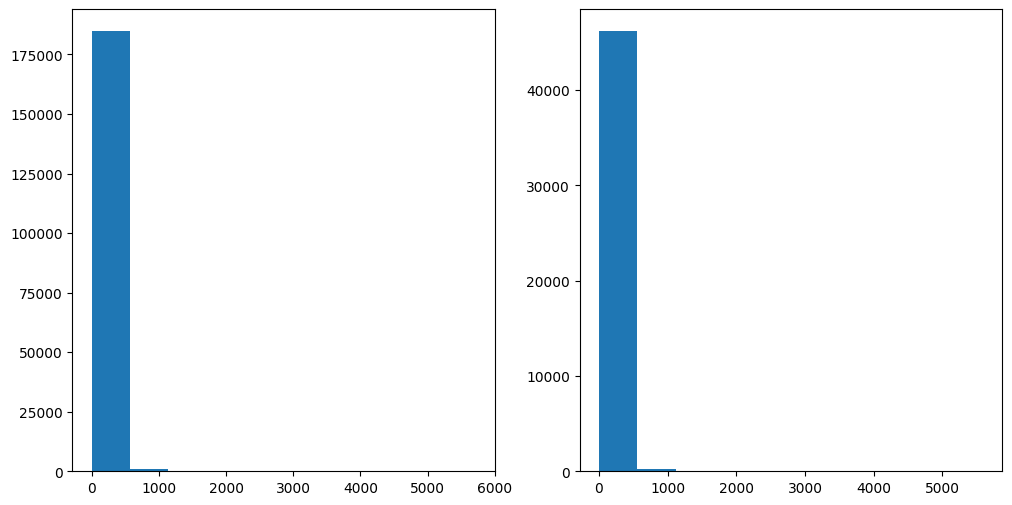

In [21]:
import matplotlib.pyplot as plt
%matplotlib inline

train_lens = [len(s) for s in train_sequences]
test_lens = [len(s) for s in test_sequences]

fig, ax = plt.subplots(1,2, figsize=(12, 6))
h1 = ax[0].hist(train_lens)
h2 = ax[1].hist(test_lens)

In [22]:
MAX_SEQUENCE_LENGTH = 200

from keras.preprocessing.sequence import pad_sequences
# pad dataset to a maximum review length in words
X_train = pad_sequences(train_sequences, maxlen=MAX_SEQUENCE_LENGTH)
X_test = pad_sequences(test_sequences, maxlen=MAX_SEQUENCE_LENGTH)
X_train.shape, X_test.shape

((185659, 200), (46415, 200))

In [23]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
num_classes=2 

In [24]:
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [35]:
y_test.shape


(46415,)

In [25]:
from tensorflow.keras.layers import Layer
from tensorflow.keras import backend as K
from tensorflow.keras.initializers import glorot_uniform
from tensorflow.keras.regularizers import get as regularizer_get
from tensorflow.keras.constraints import get as constraint_get

class AttentionLayer(Layer):
    
    def __init__(self, step_dim,
                 W_regularizer=None, b_regularizer=None,
                 W_constraint=None, b_constraint=None,
                 bias=True, **kwargs):
        
        self.supports_masking = True
        self.init = glorot_uniform()

        self.W_regularizer = regularizer_get(W_regularizer)
        self.b_regularizer = regularizer_get(b_regularizer)

        self.W_constraint = constraint_get(W_constraint)
        self.b_constraint = constraint_get(b_constraint)

        self.bias = bias
        self.step_dim = step_dim
        self.features_dim = 0
        super(AttentionLayer, self).__init__(**kwargs)
        

    def build(self, input_shape):
        assert len(input_shape) == 3

        self.W = self.add_weight(shape=(input_shape[-1],),
                                 initializer=self.init,
                                 name='{}_W'.format(self.name),
                                 regularizer=self.W_regularizer,
                                 constraint=self.W_constraint)
        self.features_dim = input_shape[-1]

        if self.bias:
            self.b = self.add_weight(shape=(input_shape[1],),
                                     initializer='zeros',
                                     name='{}_b'.format(self.name),
                                     regularizer=self.b_regularizer,
                                     constraint=self.b_constraint)
        else:
            self.b = None

        self.built = True
        

    def compute_mask(self, input, input_mask=None):
        return None

    
    def call(self, x, mask=None):
        features_dim = self.features_dim
        step_dim = self.step_dim

        eij = K.reshape(K.dot(K.reshape(x, (-1, features_dim)), 
                              K.reshape(self.W, (features_dim, 1))),
                        (-1, step_dim))

        if self.bias:
            eij += self.b

        eij = K.tanh(eij)

        a = K.exp(eij)

        if mask is not None:
            a *= K.cast(mask, K.floatx())

        a /= K.cast(K.sum(a, axis=1, keepdims=True) + K.epsilon(), K.floatx())
        a = K.expand_dims(a)
        weighted_input = x * a
        
        return K.sum(weighted_input, axis=1)

    
    def compute_output_shape(self, input_shape):
        return input_shape[0],  self.features_dim
    
    
    def get_config(self):
        config = {'step_dim': self.step_dim}
        base_config = super(AttentionLayer, self).get_config()
        return dict(list(base_config.items()) + list(config.items()))


In [48]:
from keras import initializers, regularizers, constraints, optimizers, layers
from keras.models import Model
from keras.layers import Input, Embedding, Bidirectional, LSTM, GRU, Conv1D, MaxPooling1D, Concatenate, Dense, Dropout
from keras.layers import GlobalAveragePooling1D, Attention

EMBEDDING_DIM = 200  # Dimension for dense embeddings for each token
LSTM_DIM = 50        # Total LSTM units

# Define the input sequence
sequence_input = Input(shape=(MAX_SEQUENCE_LENGTH,))
embedded_sequences = Embedding(VOCAB_SIZE, EMBEDDING_DIM, trainable=True)(sequence_input)

# Add Bidirectional LSTM
bilstm = Bidirectional(LSTM(LSTM_DIM, return_sequences=True))(embedded_sequences)

# Add Conv1D and MaxPooling layers
conv1d = Conv1D(filters=64, kernel_size=3, activation='relu', padding='same')(embedded_sequences)

# Concatenate LSTM and CNN features
concat = Concatenate()([bilstm, conv1d])

# Attention layer
# Dot-product self-attention (keras.layers.Attention), as in the reported run
att = Attention()([concat, concat])

# Apply Global Average Pooling to reduce the sequence dimension
pooled_att = GlobalAveragePooling1D()(att)

# Fully connected layer
dense1 = Dense(LSTM_DIM * 2, activation='relu', kernel_regularizer=regularizers.l2(0.01))(pooled_att)
dropout1 = Dropout(rate=0.50)(dense1)

# Output layer
outp = Dense(1, activation='sigmoid')(dropout1)

# Initialize the model
model = Model(inputs=sequence_input, outputs=outp)

# Compile the model
model.compile(
    loss='binary_crossentropy',
    optimizer=optimizers.Adam(learning_rate=0.0001),
    metrics=['accuracy']
)


In [49]:
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6             │ (None, 200)            │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ embedding_6 (Embedding)   │ (None, 200, 200)       │     15,486,000 │ input_layer_6[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bidirectional_6           │ (None, 200, 100)       │        100,400 │ embedding_6[0][0]      │
│ (Bidirectional)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_6 (Conv1D)         │ (None, 200, 64)        │         38,464 │ embedding_6[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate_6             │ (None, 200, 164)       │              0 │ bidirectional_6[0][0], │
│ (Concatenate)             │                        │                │ conv1d_6[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ attention_5 (Attention)   │ (None, 200, 164)       │              0 │ concatenate_6[0][0],   │
│                           │                        │                │ concatenate_6[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ global_average_pooling1d… │ (None, 164)            │              0 │ attention_5[0][0]      │
│ (GlobalAveragePooling1D)  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_6 (Dense)           │ (None, 100)            │         16,500 │ global_average_poolin… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_3 (Dropout)       │ (None, 100)            │              0 │ dense_6[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_7 (Dense)           │ (None, 1)              │            101 │ dropout_3[0][0]        │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 15,641,465 (59.67 MB)

 Trainable params: 15,641,465 (59.67 MB)

 Non-trainable params: 0 (0.00 B)

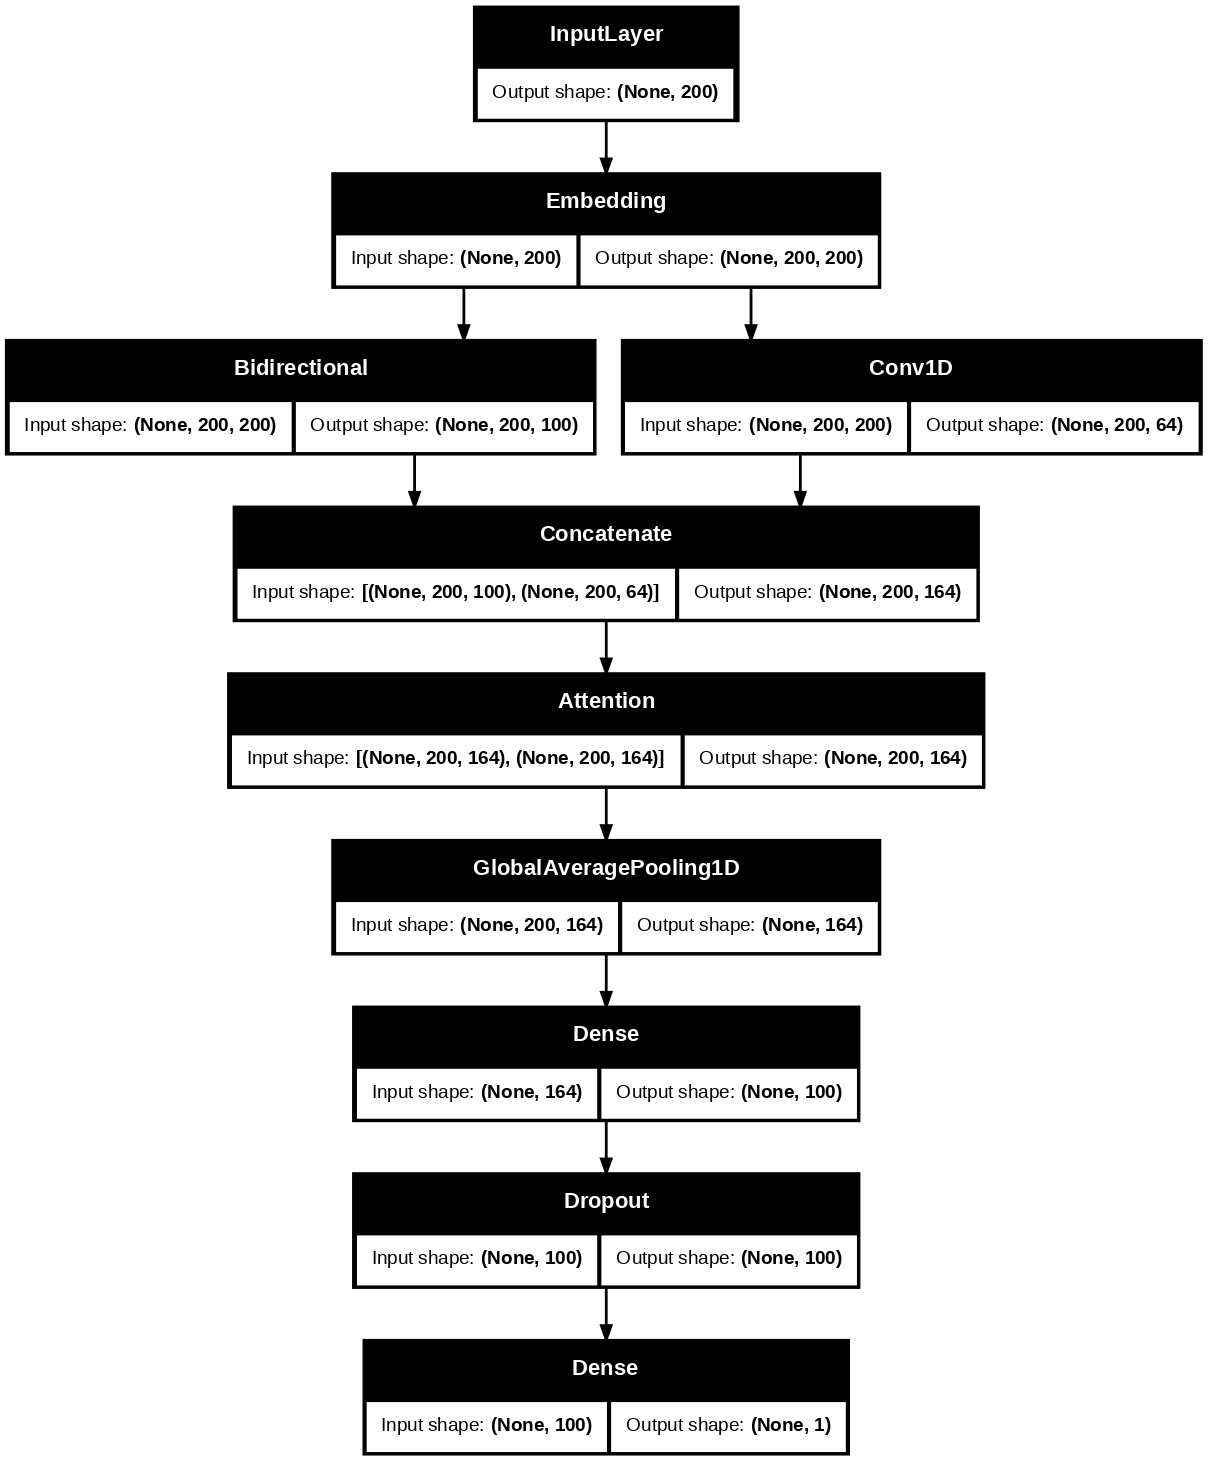

In [50]:
keras.utils.plot_model(model, show_shapes=True, dpi = 100)

In [51]:
from keras.callbacks import EarlyStopping
from keras.callbacks import ModelCheckpoint
from keras.callbacks import EarlyStopping
from keras.callbacks import ModelCheckpoint
from keras.callbacks import ReduceLROnPlateau

lrs = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)

epochs = 100
batch_size = 128

es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=10)
mc = ModelCheckpoint('./best_model/best_model_gru.keras', monitor='val_accuracy', mode='max', verbose=1, save_best_only=True)
history = model.fit(X_train, y_train,  batch_size=batch_size, shuffle=True, validation_split=0.1, epochs=epochs, verbose=1, callbacks=[es, mc, lrs])

Epoch 1/100
1305/1306 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7724 - loss: 1.2363
Epoch 1: val_accuracy improved from -inf to 0.83120, saving model to ./best_model/best_model_gru.keras
1306/1306 ━━━━━━━━━━━━━━━━━━━━ 62s 45ms/step - accuracy: 0.7725 - loss: 1.2357 - val_accuracy: 0.8312 - val_loss: 0.5235 - learning_rate: 1.0000e-04
Epoch 2/100
1305/1306 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.8614 - loss: 0.4372
Epoch 2: val_accuracy improved from 0.83120 to 0.88948, saving model to ./best_model/best_model_gru.keras
1306/1306 ━━━━━━━━━━━━━━━━━━━━ 59s 45ms/step - accuracy: 0.8614 - loss: 0.4372 - val_accuracy: 0.8895 - val_loss: 0.3187 - learning_rate: 1.0000e-04
Epoch 3/100
1305/1306 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9033 - loss: 0.2975
Epoch 3: val_accuracy improved from 0.88948 to 0.90483, saving model to ./best_model/best_model_gru.keras
1306/1306 ━━━━━━━━━━━━━━━━━━━━ 59s 45ms/step - accuracy: 0.9033 - loss: 0.2975 - val_accuracy: 0.9048 - val_loss: 0.2

In [52]:
from keras.models import load_model

# Final evaluation of the model
# load the saved model
saved_model = load_model('./best_model/best_model_gru.keras', custom_objects={'AttentionLayer': AttentionLayer})
train_acc = saved_model.evaluate(X_train, y_train, verbose=1)
test_acc = saved_model.evaluate(X_test, y_test, verbose=1)
print('Train: %.2f%%, Test: %.2f%%' % (train_acc[1]*100, test_acc[1]*100))

5802/5802 ━━━━━━━━━━━━━━━━━━━━ 56s 10ms/step - accuracy: 0.9843 - loss: 0.0561
1451/1451 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.9401 - loss: 0.1908
Train: 98.14%, Test: 94.06%


dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])


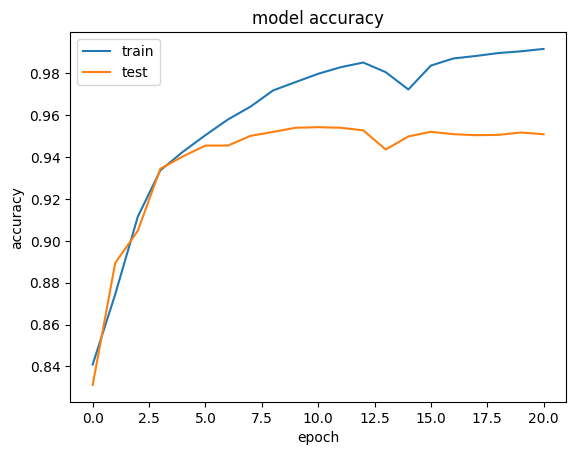

In [53]:
# list all data in history
print(history.history.keys())
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.savefig('model accuracy dropout 0.5 balance.jpg')
plt.show()

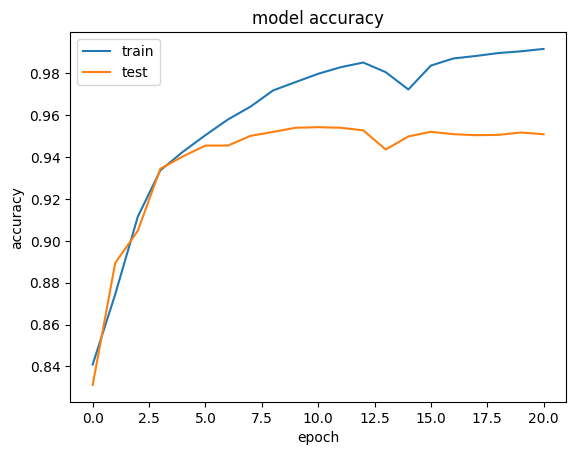

In [54]:
# summarize history for loss
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

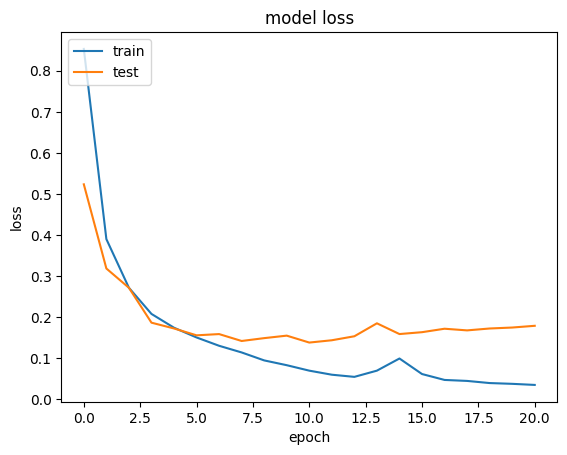

In [55]:
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [69]:
prediction_probs = saved_model.predict(X_test, verbose=1).ravel()
predictions = [1 if prob > 0.5 else 0 for prob in prediction_probs]

1451/1451 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step


In [75]:
from sklearn.metrics import confusion_matrix, classification_report

labels = ['positive', 'negative']
print(classification_report(y_test, predictions, digits=5))

pd.DataFrame(confusion_matrix(y_test, predictions), index=labels, columns=labels)

              precision    recall  f1-score   support

           0    0.92572   0.95843   0.94179     23287
           1    0.95660   0.92256   0.93927     23128

    accuracy                        0.94056     46415
   macro avg    0.94116   0.94050   0.94053     46415
weighted avg    0.94111   0.94056   0.94054     46415



,positive,negative
positive,22319,968
negative,1791,21337


In [71]:
from sklearn.metrics import roc_auc_score, roc_curve

def plot_roc_curve(y_test, y_pred):
    fpr, tpr, thresholds = roc_curve(y_test, y_pred)
    plt.plot(fpr, tpr)
    plt.plot([0, 1], ls="--")
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')

model AUC score: 0.986055595654287


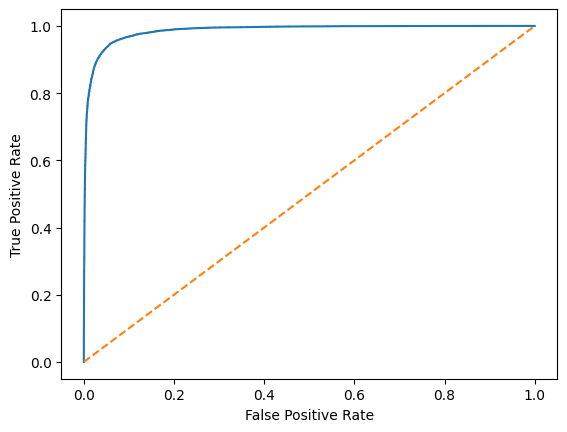

In [76]:
plot_roc_curve(y_test, prediction_probs)
print(f'model AUC score: {roc_auc_score(y_test, prediction_probs)}')

model f1 score: 0.9185635258909949 model AUC score: 0.9828190732991064


Text(0, 0.5, 'Precision')

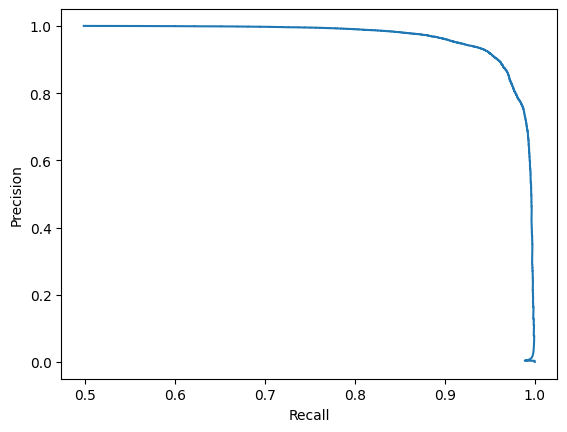

In [60]:
from sklearn.metrics import precision_recall_curve, f1_score, auc

precision, recall, thresholds = precision_recall_curve(y_test, prediction_probs)
print(f'model f1 score: {f1_score(y_test, predictions)} model AUC score: {auc(recall, precision)}')
plt.plot(precision, recall)
plt.xlabel('Recall')
plt.ylabel('Precision')